# Campaign Revenue Prediction — Linear Regression
**Intern: A. Sai Akhil | Project 1 of 2 | 10-Day Internship Prototype**

Predicts estimated campaign **revenue (INR)** using only planning-stage inputs
(budget, duration, audience size, discount, channel) — before a campaign runs.
This notebook walks through all 20 steps of the workflow, end to end, on the
**raw**, uncleaned dataset (`data/campaign_revenue_raw.csv`).

## 1. Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/campaign_revenue_raw.csv", parse_dates=["campaign_start_date"])
print(f"Loaded raw data: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded raw data: 20200 rows, 8 columns

## 2. Data Understanding

In [2]:
print("Column dtypes:")
print(df.dtypes)

Column dtypes:
campaign_id                         str
campaign_start_date      datetime64[us]
channel                             str
planned_budget_inr              float64
planned_duration_days           float64
planned_audience_size           float64
offer_discount_pct              float64
revenue_inr                     float64
dtype: object

In [3]:
df.describe(include="all").T

In [4]:
print("Missing value counts:")
print(df.isna().sum())

Missing value counts:
campaign_id                 0
campaign_start_date         0
channel                   605
planned_budget_inr       1417
planned_duration_days     808
planned_audience_size    1015
offer_discount_pct       1616
revenue_inr                 0
dtype: int64

## 3. Exploratory Data Analysis (EDA)

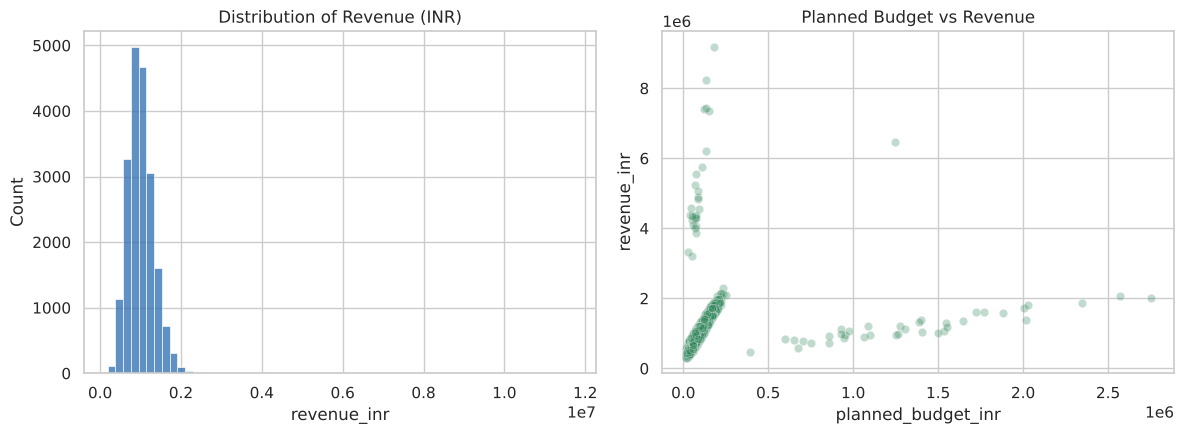

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["revenue_inr"].dropna(), bins=60, ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribution of Revenue (INR)")
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=1),
                x="planned_budget_inr", y="revenue_inr", alpha=0.3, ax=axes[1], color="#2f855a")
axes[1].set_title("Planned Budget vs Revenue")
plt.tight_layout()
plt.show()

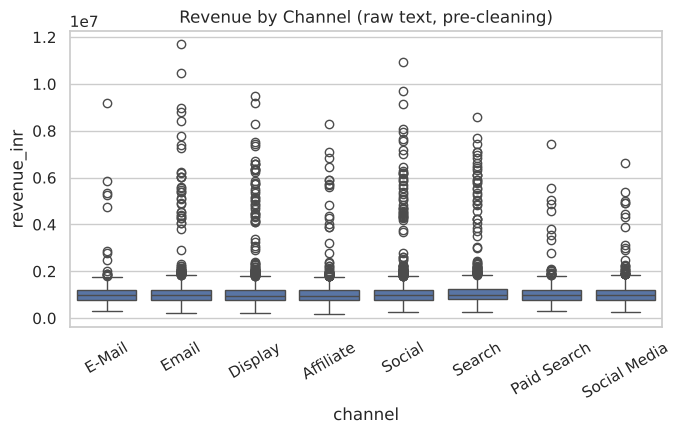

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
channel_clean_preview = df["channel"].astype(str).str.strip().str.title()
sns.boxplot(x=channel_clean_preview, y=df["revenue_inr"], ax=ax)
ax.set_title("Revenue by Channel (raw text, pre-cleaning)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

revenue_inr              1.000000
planned_audience_size    0.222668
planned_budget_inr       0.174618
planned_duration_days    0.021991
offer_discount_pct      -0.010377
Name: revenue_inr, dtype: float64

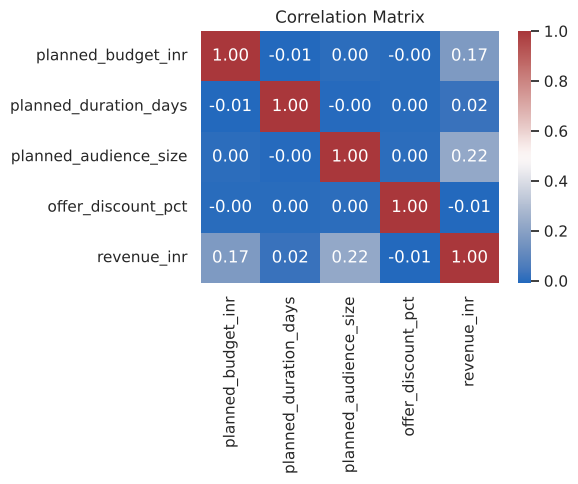

In [7]:
numeric_cols = ["planned_budget_inr", "planned_duration_days", "planned_audience_size", "offer_discount_pct", "revenue_inr"]
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()
print(corr["revenue_inr"].sort_values(ascending=False))

## 4. Data Cleaning
The raw data contains duplicate campaigns, inconsistent channel text
(`"social "`, `" SOCIAL"`, `"Social Media"`), and some sign-error negative durations.

In [8]:
before = len(df)
df = df.drop_duplicates(subset=["campaign_id"]).copy()
print(f"Removed {before - len(df)} duplicate rows (by campaign_id)")

df["channel"] = df["channel"].astype(str).str.strip().str.title()
df["channel"] = df["channel"].replace({
    "Social Media": "Social", "Paid Search": "Search", "E-Mail": "Email", "Nan": np.nan
})
print("\nCleaned channel value counts:")
print(df["channel"].value_counts(dropna=False))

neg_mask = df["planned_duration_days"] < 0
df.loc[neg_mask, "planned_duration_days"] = df.loc[neg_mask, "planned_duration_days"].abs()
print(f"\nFixed {neg_mask.sum()} negative duration values (sign error)")

Removed 200 duplicate rows (by campaign_id)

Cleaned channel value counts:
channel
Social       5398
Search       4223
Email        3853
Display      3633
Affiliate    2293
NaN           600
Name: count, dtype: int64

Fixed 78 negative duration values (sign error)

## 5. Handling Missing Values
Rows with any missing required value are **dropped** rather than imputed, so training
only ever sees genuinely observed campaign data (no guessed values standing in for real ones).

In [9]:
print("Missing values before handling:")
print(df.isna().sum())

before = len(df)
df = df.dropna().copy()
print(f"\nDropped {before - len(df)} rows containing missing values -> {len(df)} rows remain")

Missing values before handling:
campaign_id                 0
campaign_start_date         0
channel                   600
planned_budget_inr       1400
planned_duration_days     800
planned_audience_size    1000
offer_discount_pct       1600
revenue_inr                 0
dtype: int64

Dropped 4902 rows containing missing values -> 15098 rows remain

## 6. Handling Outliers
IQR-based outlier detection (1.5×IQR) is applied to `planned_budget_inr` and `revenue_inr`,
which both contain injected extreme values (data-entry / tracking errors).

In [10]:
before = len(df)
for col in ["planned_budget_inr", "revenue_inr"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] >= lower) & (df[col] <= upper)
    removed = (~mask).sum()
    df = df[mask]
    print(f"{col}: removed {removed} IQR outliers (bounds {lower:,.0f} to {upper:,.0f})")

df = df.reset_index(drop=True)
print(f"\nRows remaining after outlier removal: {len(df)} (from {before})")

planned_budget_inr: removed 474 IQR outliers (bounds -10,049 to 186,030)
revenue_inr: removed 213 IQR outliers (bounds 175,233 to 1,781,219)

Rows remaining after outlier removal: 14411 (from 15098)

## 7. Feature Selection

In [11]:
candidate_features = ["channel", "planned_budget_inr", "planned_duration_days",
                      "planned_audience_size", "offer_discount_pct"]
numeric = ["planned_budget_inr", "planned_duration_days", "planned_audience_size", "offer_discount_pct"]
corr_with_target = df[numeric + ["revenue_inr"]].corr()["revenue_inr"].drop("revenue_inr")
print("Correlation of numeric candidates with revenue_inr:")
print(corr_with_target.sort_values(ascending=False))
print(f"\nSelected features: {candidate_features}")

Correlation of numeric candidates with revenue_inr:
planned_budget_inr       0.899456
planned_audience_size    0.406498
planned_duration_days    0.040589
offer_discount_pct      -0.026250
Name: revenue_inr, dtype: float64

Selected features: ['channel', 'planned_budget_inr', 'planned_duration_days', 'planned_audience_size', 'offer_discount_pct']

## 8. Feature Engineering
Two derived features are added: cost-efficiency (`budget_per_day`) and reach-efficiency
(`audience_per_budget`).

In [12]:
df["budget_per_day"] = df["planned_budget_inr"] / df["planned_duration_days"].replace(0, np.nan)
df["audience_per_budget"] = df["planned_audience_size"] / df["planned_budget_inr"].replace(0, np.nan)
df["budget_per_day"] = df["budget_per_day"].fillna(df["budget_per_day"].median())
df["audience_per_budget"] = df["audience_per_budget"].fillna(df["audience_per_budget"].median())
print("Engineered features added: budget_per_day, audience_per_budget")
df[["budget_per_day", "audience_per_budget"]].describe()

Engineered features added: budget_per_day, audience_per_budget

## 9. Data Preprocessing
Numeric and categorical features are defined, and the cleaned dataset is saved.

In [13]:
numeric_features = ["planned_budget_inr", "planned_duration_days", "planned_audience_size",
                    "offer_discount_pct", "budget_per_day", "audience_per_budget"]
categorical_features = ["channel"]
feature_cols = numeric_features + categorical_features
target_col = "revenue_inr"

df.to_csv("../data/campaign_revenue_clean.csv", index=False)
print(f"Cleaned dataset saved: {df.shape[0]} rows -> ../data/campaign_revenue_clean.csv")
print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Cleaned dataset saved: 14411 rows -> ../data/campaign_revenue_clean.csv
Numeric features: ['planned_budget_inr', 'planned_duration_days', 'planned_audience_size', 'offer_discount_pct', 'budget_per_day', 'audience_per_budget']
Categorical features: ['channel']

## 10. Encoding Categorical Variables
`channel` is one-hot encoded. `handle_unknown="ignore"` protects the model at inference
time against a channel value it has never seen during training.

In [14]:
from sklearn.preprocessing import OneHotEncoder

ohe_preview = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_preview.fit(df[["channel"]])
print("One-hot categories learned:", ohe_preview.categories_)

One-hot categories learned: [array(['Affiliate', 'Display', 'Email', 'Search', 'Social'], dtype=object)]

## 11. Feature Scaling
Numeric features are standardized (zero mean, unit variance) with `StandardScaler`, combined
with the one-hot encoding above into a single `ColumnTransformer`.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
print("Preprocessor defined:")
print(preprocessor)

Preprocessor defined:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['planned_budget_inr', 'planned_duration_days',
                                  'planned_audience_size', 'offer_discount_pct',
                                  'budget_per_day', 'audience_per_budget']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['channel'])])

## 12. Train-Test Splitting
The `ColumnTransformer` above is only *fit* once wrapped in a `Pipeline` and trained on the
training split — so scaling/encoding statistics never leak information from the test set.

In [16]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 11528 rows | Test: 2883 rows

## 13. Model Selection

In [17]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor

candidate_models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=5000),
}
print("Candidate models:", list(candidate_models.keys()), "(plus a mean-revenue baseline)")

Candidate models: ['LinearRegression', 'Ridge', 'Lasso'] (plus a mean-revenue baseline)

## 14. Model Training

In [18]:
from sklearn.pipeline import Pipeline

fitted_pipelines = {}
for name, model in candidate_models.items():
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

baseline_pipe = Pipeline([("pre", preprocessor), ("model", DummyRegressor(strategy="mean"))])
baseline_pipe.fit(X_train, y_train)
fitted_pipelines["MeanBaseline"] = baseline_pipe

print("Trained models:", list(fitted_pipelines.keys()))

Trained models: ['LinearRegression', 'Ridge', 'Lasso', 'MeanBaseline']

## 15. Model Evaluation
MAE, RMSE and R² are reported on the held-out test set for every candidate, compared
against the mean-revenue baseline.

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
for name, pipe in fitted_pipelines.items():
    preds = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

           model           MAE          RMSE        R2
LinearRegression   7286.299541   9124.630125  0.998979
           Ridge   7286.645959   9124.373178  0.998979
           Lasso   7286.280093   9124.562490  0.998979
    MeanBaseline 233032.817756 285626.374487 -0.000267

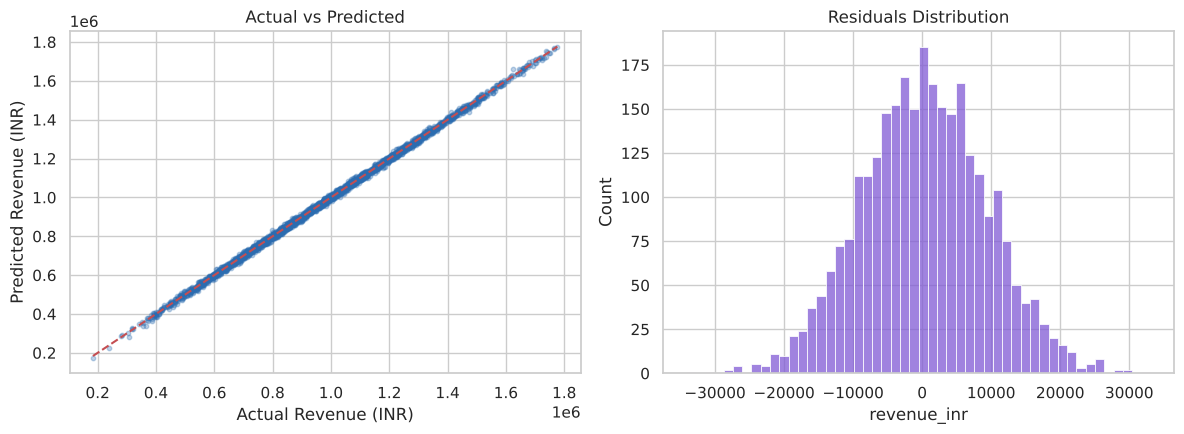

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
best_preview = fitted_pipelines["LinearRegression"]
preds_preview = best_preview.predict(X_test)
ax[0].scatter(y_test, preds_preview, alpha=0.3, s=10, color="#2b6cb0")
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set_xlabel("Actual Revenue (INR)")
ax[0].set_ylabel("Predicted Revenue (INR)")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - preds_preview
sns.histplot(residuals, bins=50, ax=ax[1], color="#805ad5")
ax[1].set_title("Residuals Distribution")
plt.tight_layout()
plt.show()

## 16. Hyperparameter Tuning
`Ridge`'s `alpha` is tuned via 5-fold cross-validated grid search, optimizing R².

In [21]:
from sklearn.model_selection import GridSearchCV

tuning_pipe = Pipeline([("pre", preprocessor), ("model", Ridge())])
param_grid = {"model__alpha": [0.01, 0.1, 1.0, 5.0, 10.0, 50.0]}
grid = GridSearchCV(tuning_pipe, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"Best Ridge alpha: {grid.best_params_}")
print(f"Best CV R2: {grid.best_score_:.4f}")

Best Ridge alpha: {'model__alpha': 0.01}
Best CV R2: 0.9990

## 17. Model Optimization

In [22]:
best_pipe = grid.best_estimator_
test_preds = best_pipe.predict(X_test)
test_r2 = r2_score(y_test, test_preds)
test_mae = mean_absolute_error(y_test, test_preds)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
print(f"Tuned Ridge — Test MAE: {test_mae:,.0f} | Test RMSE: {test_rmse:,.0f} | Test R2: {test_r2:.4f}")

final_metrics = {"model": "FinalTunedModel", "MAE": test_mae, "RMSE": test_rmse, "R2": test_r2}
results_df = pd.concat([results_df, pd.DataFrame([final_metrics])], ignore_index=True)
results_df.to_csv("../model/model_comparison.csv", index=False)
print("\nFinal comparison table:")
print(results_df.to_string(index=False))

Tuned Ridge — Test MAE: 7,286 | Test RMSE: 9,125 | Test R2: 0.9990

Final comparison table:
           model           MAE          RMSE        R2
LinearRegression   7286.299541   9124.630125  0.998979
           Ridge   7286.645959   9124.373178  0.998979
           Lasso   7286.280093   9124.562490  0.998979
    MeanBaseline 233032.817756 285626.374487 -0.000267
 FinalTunedModel   7286.302577   9124.627072  0.998979

## 18. Model Saving

In [23]:
import joblib, json

joblib.dump(best_pipe, "../model/revenue_model_pipeline.pkl")
meta = {"feature_columns": feature_cols, "target": target_col, "metrics": final_metrics}
with open("../model/model_metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)
print("Saved pipeline -> ../model/revenue_model_pipeline.pkl")
print("Saved metadata -> ../model/model_metadata.json")

Saved pipeline -> ../model/revenue_model_pipeline.pkl
Saved metadata -> ../model/model_metadata.json

## 19. Prediction

In [24]:
sample = pd.DataFrame([{
    "channel": "Search",
    "planned_budget_inr": 150000,
    "planned_duration_days": 21,
    "planned_audience_size": 120000,
    "offer_discount_pct": 10,
    "budget_per_day": 150000 / 21,
    "audience_per_budget": 120000 / 150000,
}])[feature_cols]

pred = best_pipe.predict(sample)[0]
print(f"Sample prediction for a Search campaign: INR {pred:,.0f}")

Sample prediction for a Search campaign: INR 1,368,931

## 20. Model Deployment
The saved pipeline (`model/revenue_model_pipeline.pkl`) is loaded inside `app.py`, a
Streamlit dashboard providing:
- A labelled input form (channel, budget, duration, audience size, discount %) with a
  Predict button and a live model-performance summary.
- A batch CSV upload tab with validation, prediction, and downloadable export.
- Input-range warnings for values outside what the model was trained on.

Run it with:
```bash
streamlit run app.py
```